# 03 - Luồng B (cải tiến) và ablation
Luồng B gồm hai thay đổi so với Luồng A:
1. **Đặc trưng mới** (B1): tỷ lệ môn đạt trên môn đăng ký, tỷ lệ đạt trên lượt thi, chênh lệch điểm hai kỳ, tổng môn đạt. Tính theo từng dòng nên không gây data leakage.
2. **One-Hot** (B2) cho 9 cột mã định danh (`min_frequency=20` gộp giá trị hiếm).

**B** = B1 + B2. Ablation giúp tách xem thay đổi nào thật sự có ích.

In [1]:
import sys
sys.path.append("../src")
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.model_selection import GridSearchCV, cross_validate

from data import load_data, split_data, get_cv, TARGET, RANDOM_STATE
from models import make_pipeline, MODELS, MODEL_NAMES, DEFAULT_PARAMS, PARAM_GRIDS
from evaluate import evaluate

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RES = Path("../results"); FIG = Path("../reports/figures")
df = load_data()
Xtr, Xte, ytr, yte = split_data(df)   # 80/20, stratify, random_state=42
cv = get_cv()                         # StratifiedKFold(5, shuffle=True, random_state=42)
print(Xtr.shape, Xte.shape)

(3539, 36) (885, 36)


## 1. Đặc trưng mới

In [2]:
from features import add_features
Xf = add_features(Xtr)
new_cols = [c for c in Xf.columns if c not in Xtr.columns]
print(new_cols)
tmp = Xf[new_cols].assign(Target_code=ytr.map({"Dropout": 0, "Enrolled": 1, "Graduate": 2}))
tmp.corr()["Target_code"].drop("Target_code").round(3)

['approval_rate_1st', 'eval_pass_rate_1st', 'approval_rate_2nd', 'eval_pass_rate_2nd', 'grade_delta', 'total_approved']


approval_rate_1st     0.623
eval_pass_rate_1st    0.626
approval_rate_2nd     0.698
eval_pass_rate_2nd    0.690
grade_delta           0.209
total_approved        0.583
Name: Target_code, dtype: float64

In [3]:
# So với các cột gốc tương ứng
orig = ["Curricular units 1st sem (approved)", "Curricular units 2nd sem (approved)",
        "Curricular units 2nd sem (grade)"]
pd.concat([Xtr[orig], Xf[["approval_rate_2nd", "eval_pass_rate_2nd"]]], axis=1)\
  .assign(Target_code=ytr.map({"Dropout": 0, "Enrolled": 1, "Graduate": 2})).corr()["Target_code"].round(3)

Curricular units 1st sem (approved)    0.521
Curricular units 2nd sem (approved)    0.618
Curricular units 2nd sem (grade)       0.567
approval_rate_2nd                      0.698
eval_pass_rate_2nd                     0.690
Target_code                            1.000
Name: Target_code, dtype: float64

## 2. Pipeline Luồng B

In [4]:
pipe = make_pipeline("B", "knn", **DEFAULT_PARAMS["knn"]).fit(Xtr, ytr)
names = pipe.named_steps["prep"].get_feature_names_out()
print("Số cột sau tiền xử lý:", len(names), "(Luồng A:", Xtr.shape[1], ")")
print(list(names[:6]), "...", list(names[-6:]))
pipe

Số cột sau tiền xử lý: 125 (Luồng A: 36 )
['Marital status_1', 'Marital status_2', 'Marital status_4', 'Marital status_infrequent_sklearn', 'Application mode_1', 'Application mode_7'] ... ['approval_rate_1st', 'eval_pass_rate_1st', 'approval_rate_2nd', 'eval_pass_rate_2nd', 'grade_delta', 'total_approved']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Dropout','Enrolled','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['Marital status','Application mode','Application order',..., 'Unemployment rate','Inflation rate','GDP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transform

## 3. Ablation: A, B1, B2, B
Đọc kết quả đã chạy bởi `src/run_experiments.py`.

In [9]:
d = pd.read_csv(RES / "ablation_default_f1.csv", index_col=0).round(3)
t = pd.read_csv(RES / "ablation_tuned_f1.csv", index_col=0).round(3)
print("F1-macro trên test, mô hình MẶC ĐỊNH"); display(d)
print("F1-macro trên test, mô hình TINH CHỈNH"); display(t)
tuned = pd.read_csv(RES / "tuned_models.csv")
print("F1-macro CV (trung bình ± độ lệch chuẩn), TINH CHỈNH")
tuned["cv"] = tuned.cv_f1_macro.round(3).astype(str) + " ± " + tuned.cv_std.round(3).astype(str)
display(tuned.pivot(index="model", columns="flow", values="cv")[["A", "B1", "B2", "B"]])

F1-macro trên test, mô hình MẶC ĐỊNH


,A,B1,B2,B
model,,,,
dt,0.639,0.608,0.637,0.610
knn,0.573,0.620,0.619,0.664
nb,0.558,0.647,0.302,0.339


F1-macro trên test, mô hình TINH CHỈNH


,A,B1,B2,B
model,,,,
dt,0.650,0.663,0.656,0.673
knn,0.621,0.648,0.607,0.685
nb,0.557,0.647,0.615,0.669


F1-macro CV (trung bình ± độ lệch chuẩn), TINH CHỈNH


flow,A,B1,B2,B
model,,,,
dt,0.683 ± 0.014,0.687 ± 0.01,0.675 ± 0.017,0.686 ± 0.01
knn,0.633 ± 0.014,0.668 ± 0.014,0.626 ± 0.012,0.675 ± 0.019
nb,0.576 ± 0.021,0.658 ± 0.021,0.623 ± 0.02,0.671 ± 0.012


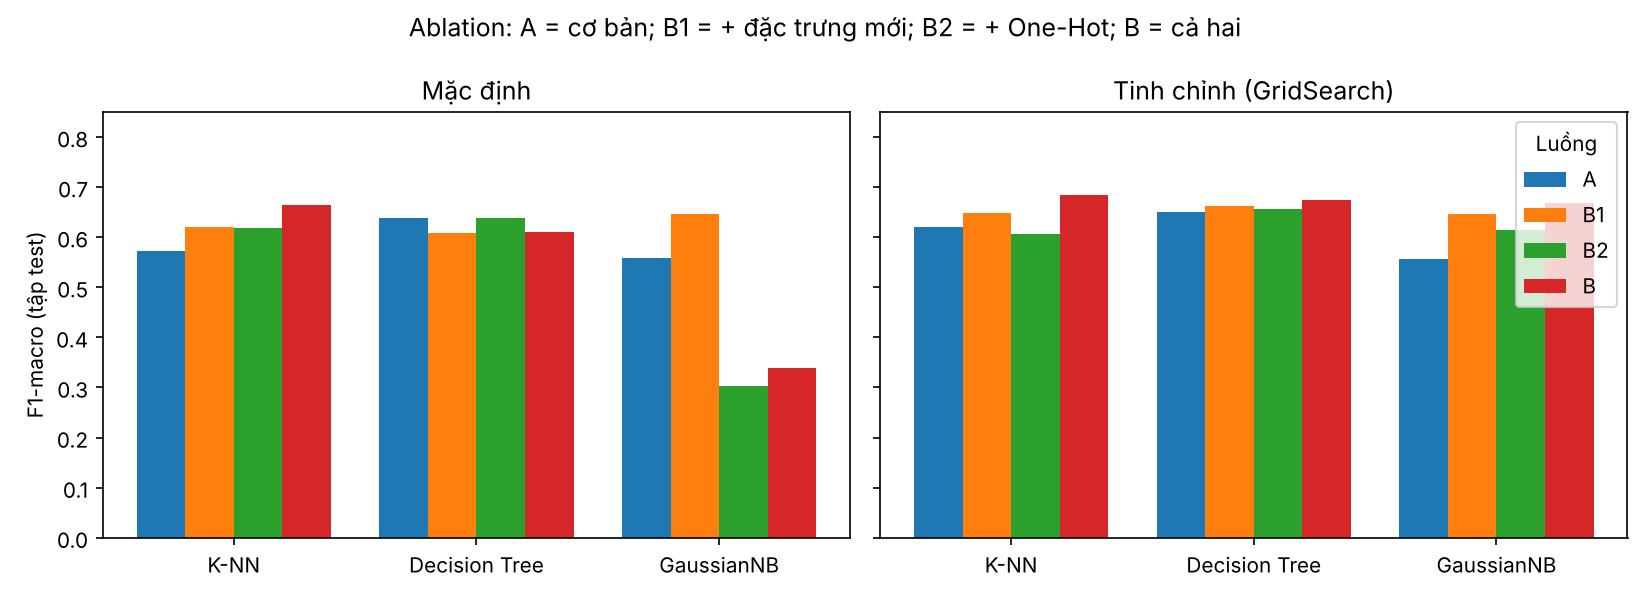

In [10]:
display(Image(filename=str(FIG / "res_02_ablation.png")))

## 4. Vì sao Naive Bayes mặc định sụp đổ trên Luồng B?
GaussianNB với `var_smoothing=1e-9` gần như chia cho phương sai bằng 0 ở các cột One-Hot hiếm. Thử tăng `var_smoothing`:

In [11]:
rows = []
for vs in [1e-9, 1e-5, 1e-3, 1e-1, 1.0]:
    p = make_pipeline("B", "nb", var_smoothing=vs).fit(Xtr, ytr)
    e = evaluate(yte, p.predict(Xte))
    rows.append({"var_smoothing": vs, "test_acc": e["test_acc"], "test_f1_macro": e["test_f1_macro"],
                 "recall_Enrolled": e["recall_Enrolled"]})
pd.DataFrame(rows).round(3)

,var_smoothing,test_acc,test_f1_macro,recall_Enrolled
0,0.000,0.341,0.339,0.937
1,0.000,0.562,0.562,0.818
2,0.001,0.628,0.606,0.654
3,0.100,0.731,0.669,0.472
4,1.000,0.722,0.644,0.409


**Ghi chú cho báo cáo:** khi `var_smoothing` nhỏ, mô hình đoán gần như mọi mẫu là `Enrolled` (recall Enrolled xấp xỉ 0,94 nhưng Accuracy xấp xỉ 0,34). Tăng `var_smoothing` lên 0,1 khôi phục hiệu năng. Đây là minh chứng rằng một cách mã hóa tốt cho thuật toán này (cây, K-NN) có thể làm hỏng thuật toán khác, nên phải tinh chỉnh tham số theo luồng.

## 5. Độ nhạy tham số

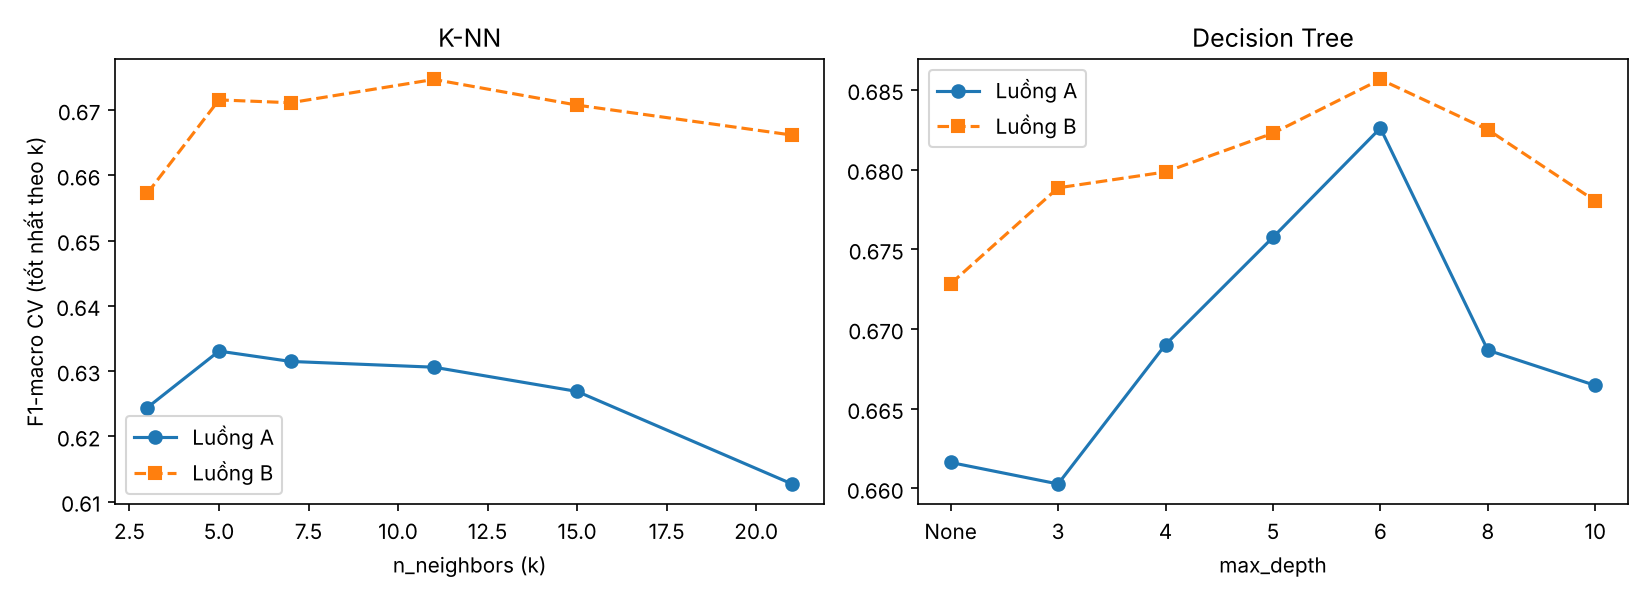

In [12]:
display(Image(filename=str(FIG / "res_03_sensitivity.png")))